<a href="https://colab.research.google.com/github/moiz-shahid/Deep-Learning-Tutorials/blob/main/Tutorial-08-Faster-RCNN-Object-Detection/DL_Tutorial_8.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [1]:
import torch
import torch.nn as nn
import torch.nn.functional as F
import torchvision
import numpy as np
import matplotlib.pyplot as plt

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

print("PyTorch version:", torch.__version__)
print("Torchvision version:", torchvision.__version__)
print("Using device:", device)

PyTorch version: 2.14.1+cu130
Torchvision version: 0.29.1+cu130
Using device: cuda


In [2]:
class CustomBackbone(nn.Module):
    def __init__(self):
        super(CustomBackbone, self).__init__()

        self.features = nn.Sequential(
            # First convolution block
            nn.Conv2d(3, 64, kernel_size=3, padding=1),
            nn.ReLU(),
            nn.MaxPool2d(kernel_size=2),

            # Second convolution block
            nn.Conv2d(64, 128, kernel_size=3, padding=1),
            nn.ReLU(),
            nn.MaxPool2d(kernel_size=2),

            # Third convolution block
            nn.Conv2d(128, 256, kernel_size=3, padding=1),
            nn.ReLU(),
            nn.MaxPool2d(kernel_size=2),

            # Fourth convolution layer
            nn.Conv2d(256, 512, kernel_size=3, padding=1),
            nn.ReLU()
        )

    def forward(self, x):
        return self.features(x)


backbone = CustomBackbone().to(device)

print(backbone)

CustomBackbone(
  (features): Sequential(
    (0): Conv2d(3, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (1): ReLU()
    (2): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
    (3): Conv2d(64, 128, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (4): ReLU()
    (5): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
    (6): Conv2d(128, 256, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (7): ReLU()
    (8): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
    (9): Conv2d(256, 512, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (10): ReLU()
  )
)


In [3]:
# Create a random input image
dummy_image = torch.randn(1, 3, 224, 224).to(device)

# Pass the image through the backbone
with torch.no_grad():
    feature_map = backbone(dummy_image)

print("Input shape:", dummy_image.shape)
print("Feature map shape:", feature_map.shape)

Input shape: torch.Size([1, 3, 224, 224])
Feature map shape: torch.Size([1, 512, 28, 28])


In [4]:
class RegionProposalNetwork(nn.Module):
    def __init__(self, in_channels=512, num_anchors=9):
        super(RegionProposalNetwork, self).__init__()

        # Shared convolution
        self.rpn_conv = nn.Conv2d(
            in_channels, 512,
            kernel_size=3, padding=1
        )

        # Object / background classification
        self.rpn_class = nn.Conv2d(
            512, num_anchors * 2,
            kernel_size=1
        )

        # Bounding box regression
        self.rpn_bbox = nn.Conv2d(
            512, num_anchors * 4,
            kernel_size=1
        )

    def forward(self, feature_map):

        x = F.relu(self.rpn_conv(feature_map))

        objectness = self.rpn_class(x)

        bbox_regression = self.rpn_bbox(x)

        return objectness, bbox_regression


# Initialize RPN
rpn = RegionProposalNetwork().to(device)

print(rpn)

RegionProposalNetwork(
  (rpn_conv): Conv2d(512, 512, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
  (rpn_class): Conv2d(512, 18, kernel_size=(1, 1), stride=(1, 1))
  (rpn_bbox): Conv2d(512, 36, kernel_size=(1, 1), stride=(1, 1))
)


In [5]:
# Pass previously generated backbone features to RPN
with torch.no_grad():
    objectness, bbox_regression = rpn(feature_map)

print("Backbone output:", feature_map.shape)
print("Objectness output:", objectness.shape)
print("BBox regression output:", bbox_regression.shape)

Backbone output: torch.Size([1, 512, 28, 28])
Objectness output: torch.Size([1, 18, 28, 28])
BBox regression output: torch.Size([1, 36, 28, 28])


In [6]:
from torchvision.ops import roi_pool

class ROIPoolingLayer(nn.Module):
    def __init__(self, output_size=(7, 7), spatial_scale=1/8):
        super(ROIPoolingLayer, self).__init__()

        self.output_size = output_size
        self.spatial_scale = spatial_scale

    def forward(self, feature_map, rois):

        pooled_features = roi_pool(
            input=feature_map,
            boxes=rois,
            output_size=self.output_size,
            spatial_scale=self.spatial_scale
        )

        return pooled_features


roi_pooling_layer = ROIPoolingLayer().to(device)

print(roi_pooling_layer)

ROIPoolingLayer()


In [7]:
# Three example ROIs in original image coordinates
# Format: [x_min, y_min, x_max, y_max]

rois = [
    torch.tensor([
        [20, 30, 100, 120],
        [60, 50, 180, 200],
        [100, 80, 210, 190]
    ], dtype=torch.float32, device=device)
]

# Perform ROI Pooling
with torch.no_grad():
    pooled_features = roi_pooling_layer(feature_map, rois)

print("Original feature map:", feature_map.shape)
print("Number of ROIs:", len(rois[0]))
print("Pooled features:", pooled_features.shape)

Original feature map: torch.Size([1, 512, 28, 28])
Number of ROIs: 3
Pooled features: torch.Size([3, 512, 7, 7])


In [8]:
class DetectionHeads(nn.Module):
    def __init__(self, in_channels=512, num_classes=3):
        super(DetectionHeads, self).__init__()

        self.flatten = nn.Flatten()

        self.fc = nn.Sequential(
            nn.Linear(in_channels * 7 * 7, 1024),
            nn.ReLU()
        )

        # Classification head
        self.classifier = nn.Linear(1024, num_classes)

        # Bounding box regression head
        self.bbox_regressor = nn.Linear(
            1024, num_classes * 4
        )

    def forward(self, pooled_features):

        x = self.flatten(pooled_features)
        x = self.fc(x)

        class_scores = self.classifier(x)
        bbox_deltas = self.bbox_regressor(x)

        return class_scores, bbox_deltas


num_classes = 3  # Background + 2 example object classes

detection_heads = DetectionHeads(
    num_classes=num_classes
).to(device)

print(detection_heads)

DetectionHeads(
  (flatten): Flatten(start_dim=1, end_dim=-1)
  (fc): Sequential(
    (0): Linear(in_features=25088, out_features=1024, bias=True)
    (1): ReLU()
  )
  (classifier): Linear(in_features=1024, out_features=3, bias=True)
  (bbox_regressor): Linear(in_features=1024, out_features=12, bias=True)
)


In [9]:
with torch.no_grad():
    class_scores, bbox_deltas = detection_heads(pooled_features)

print("ROI pooled features:", pooled_features.shape)
print("Classification output:", class_scores.shape)
print("Regression output:", bbox_deltas.shape)

ROI pooled features: torch.Size([3, 512, 7, 7])
Classification output: torch.Size([3, 3])
Regression output: torch.Size([3, 12])


In [10]:
class CustomFasterRCNN(nn.Module):
    def __init__(self, num_classes=3):
        super(CustomFasterRCNN, self).__init__()

        self.backbone = CustomBackbone()

        self.rpn = RegionProposalNetwork(
            in_channels=512,
            num_anchors=9
        )

        self.roi_pool = ROIPoolingLayer(
            output_size=(7, 7),
            spatial_scale=1/8
        )

        self.heads = DetectionHeads(
            in_channels=512,
            num_classes=num_classes
        )

    def forward(self, images, rois):

        # Backbone
        feature_maps = self.backbone(images)

        # Region Proposal Network
        rpn_objectness, rpn_bbox = self.rpn(feature_maps)

        # ROI Pooling
        pooled_features = self.roi_pool(feature_maps, rois)

        # Classification and regression
        class_scores, bbox_deltas = self.heads(pooled_features)

        return {
            "rpn_objectness": rpn_objectness,
            "rpn_bbox": rpn_bbox,
            "class_scores": class_scores,
            "bbox_deltas": bbox_deltas
        }


custom_faster_rcnn = CustomFasterRCNN(
    num_classes=num_classes
).to(device)

print(custom_faster_rcnn)

CustomFasterRCNN(
  (backbone): CustomBackbone(
    (features): Sequential(
      (0): Conv2d(3, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
      (1): ReLU()
      (2): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
      (3): Conv2d(64, 128, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
      (4): ReLU()
      (5): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
      (6): Conv2d(128, 256, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
      (7): ReLU()
      (8): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
      (9): Conv2d(256, 512, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
      (10): ReLU()
    )
  )
  (rpn): RegionProposalNetwork(
    (rpn_conv): Conv2d(512, 512, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (rpn_class): Conv2d(512, 18, kernel_size=(1, 1), stride=(1, 1))
    (rpn_bbox): Conv2d(512, 36, kernel_size=(1, 1), stride=(1, 1))
  )
  (roi_pool): RO

In [11]:
custom_faster_rcnn.eval()

with torch.no_grad():
    outputs = custom_faster_rcnn(dummy_image, rois)

print("MODEL OUTPUT SHAPES")
print("-" * 45)

for name, output in outputs.items():
    print(f"{name}: {tuple(output.shape)}")

total_params = sum(
    p.numel() for p in custom_faster_rcnn.parameters()
)

trainable_params = sum(
    p.numel()
    for p in custom_faster_rcnn.parameters()
    if p.requires_grad
)

print("\nTotal parameters:", f"{total_params:,}")
print("Trainable parameters:", f"{trainable_params:,}")

MODEL OUTPUT SHAPES
---------------------------------------------
rpn_objectness: (1, 18, 28, 28)
rpn_bbox: (1, 36, 28, 28)
class_scores: (3, 3)
bbox_deltas: (3, 12)

Total parameters: 29,644,997
Trainable parameters: 29,644,997


In [12]:
def calculate_iou(box1, box2):

    x1 = max(box1[0], box2[0])
    y1 = max(box1[1], box2[1])

    x2 = min(box1[2], box2[2])
    y2 = min(box1[3], box2[3])

    intersection = max(0, x2 - x1) * max(0, y2 - y1)

    area1 = max(0, box1[2] - box1[0]) * max(0, box1[3] - box1[1])
    area2 = max(0, box2[2] - box2[0]) * max(0, box2[3] - box2[1])

    union = area1 + area2 - intersection

    return intersection / union if union > 0 else 0.0


box1 = [10, 10, 50, 50]
box2 = [30, 30, 70, 70]

iou = calculate_iou(box1, box2)

print(f"IoU: {iou:.4f}")

IoU: 0.1429


In [13]:
def calculate_precision_recall(
    pred_boxes, pred_scores, pred_labels,
    gt_boxes, gt_labels,
    iou_threshold=0.5,
    score_threshold=0.5
):
    tp = 0
    fp = 0
    matched_gt = set()

    # Evaluate highest confidence predictions first
    sorted_indices = sorted(
        range(len(pred_scores)),
        key=lambda i: pred_scores[i],
        reverse=True
    )

    for i in sorted_indices:

        if pred_scores[i] < score_threshold:
            continue

        best_iou = 0
        best_gt_index = -1

        for j, gt_box in enumerate(gt_boxes):

            if pred_labels[i] != gt_labels[j]:
                continue

            if j in matched_gt:
                continue

            iou = calculate_iou(pred_boxes[i], gt_box)

            if iou > best_iou:
                best_iou = iou
                best_gt_index = j

        if best_iou >= iou_threshold:
            tp += 1
            matched_gt.add(best_gt_index)
        else:
            fp += 1

    fn = len(gt_boxes) - len(matched_gt)

    precision = tp / (tp + fp) if (tp + fp) else 0
    recall = tp / (tp + fn) if (tp + fn) else 0

    return precision, recall, tp, fp, fn

In [14]:
pred_boxes = [
    [10, 10, 50, 50],
    [60, 60, 100, 100],
    [120, 120, 160, 160]
]

pred_scores = [0.95, 0.90, 0.80]
pred_labels = [1, 2, 1]

gt_boxes = [
    [12, 12, 52, 52],
    [62, 62, 102, 102]
]

gt_labels = [1, 2]

precision, recall, tp, fp, fn = calculate_precision_recall(
    pred_boxes,
    pred_scores,
    pred_labels,
    gt_boxes,
    gt_labels
)

print("True Positives:", tp)
print("False Positives:", fp)
print("False Negatives:", fn)
print("Precision:", round(precision, 4))
print("Recall:", round(recall, 4))

True Positives: 2
False Positives: 1
False Negatives: 0
Precision: 0.6667
Recall: 1.0


In [15]:
def calculate_ap(precisions, recalls):

    precisions = np.array(precisions, dtype=float)
    recalls = np.array(recalls, dtype=float)

    # Add boundary points
    precisions = np.concatenate(([0.0], precisions, [0.0]))
    recalls = np.concatenate(([0.0], recalls, [1.0]))

    # Precision envelope
    for i in range(len(precisions) - 2, -1, -1):
        precisions[i] = max(precisions[i], precisions[i + 1])

    # Integrate precision-recall curve
    indices = np.where(recalls[1:] != recalls[:-1])[0]

    ap = np.sum(
        (recalls[indices + 1] - recalls[indices]) *
        precisions[indices + 1]
    )

    return float(ap)

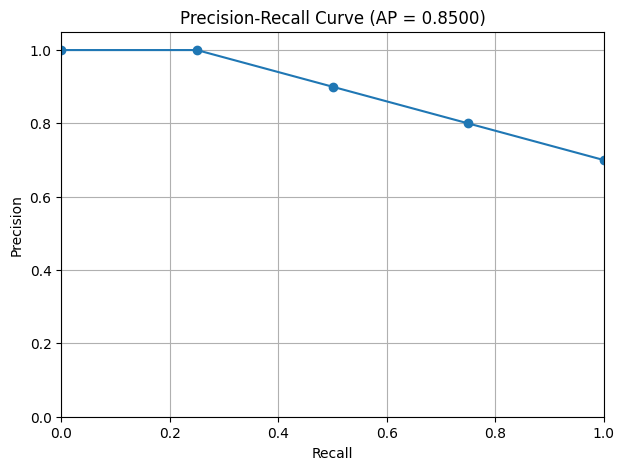

Average Precision: 0.8500


In [16]:
recalls = [0.0, 0.25, 0.50, 0.75, 1.0]
precisions = [1.0, 1.0, 0.90, 0.80, 0.70]

ap = calculate_ap(precisions, recalls)

plt.figure(figsize=(7, 5))
plt.plot(recalls, precisions, marker='o')
plt.xlabel("Recall")
plt.ylabel("Precision")
plt.title(f"Precision-Recall Curve (AP = {ap:.4f})")
plt.xlim(0, 1)
plt.ylim(0, 1.05)
plt.grid(True)
plt.show()

print(f"Average Precision: {ap:.4f}")

In [17]:
def calculate_map(predictions, ground_truths, num_classes,
                  iou_threshold=0.5):

    average_precisions = []

    # Class 0 is reserved for background
    for class_id in range(1, num_classes):

        class_predictions = []
        gt_by_image = {}
        total_gt = 0

        for image_id, (pred, gt) in enumerate(
            zip(predictions, ground_truths)
        ):
            gt_indices = [
                i for i, label in enumerate(gt["labels"])
                if label == class_id
            ]

            gt_by_image[image_id] = {
                "boxes": [gt["boxes"][i] for i in gt_indices],
                "matched": set()
            }

            total_gt += len(gt_indices)

            for i, label in enumerate(pred["labels"]):
                if label == class_id:
                    class_predictions.append({
                        "image_id": image_id,
                        "box": pred["boxes"][i],
                        "score": pred["scores"][i]
                    })

        # Classes without GT are excluded
        if total_gt == 0:
            continue

        class_predictions.sort(
            key=lambda p: p["score"],
            reverse=True
        )

        tp = np.zeros(len(class_predictions))
        fp = np.zeros(len(class_predictions))

        for k, prediction in enumerate(class_predictions):

            image_id = prediction["image_id"]
            gt_data = gt_by_image[image_id]

            best_iou = 0
            best_index = -1

            for j, gt_box in enumerate(gt_data["boxes"]):
                iou = calculate_iou(
                    prediction["box"], gt_box
                )

                if iou > best_iou:
                    best_iou = iou
                    best_index = j

            if best_iou >= iou_threshold:
                if best_index not in gt_data["matched"]:
                    tp[k] = 1
                    gt_data["matched"].add(best_index)
                else:
                    fp[k] = 1
            else:
                fp[k] = 1

        cumulative_tp = np.cumsum(tp)
        cumulative_fp = np.cumsum(fp)

        recalls = cumulative_tp / total_gt
        precisions = cumulative_tp / np.maximum(
            cumulative_tp + cumulative_fp, 1e-10
        )

        ap = calculate_ap(precisions, recalls)
        average_precisions.append(ap)

        print(f"Class {class_id} AP: {ap:.4f}")

    if not average_precisions:
        return 0.0

    return float(np.mean(average_precisions))

#Task 1: Change the Number of CNN Layers

In [18]:
import os
import urllib.request
import zipfile

dataset_url = "https://www.cis.upenn.edu/~jshi/ped_html/PennFudanPed.zip"
zip_path = "/content/PennFudanPed.zip"
dataset_dir = "/content/PennFudanPed"

if not os.path.exists(dataset_dir):
    urllib.request.urlretrieve(dataset_url, zip_path)

    with zipfile.ZipFile(zip_path, "r") as zip_ref:
        zip_ref.extractall("/content")

print("Dataset ready!")
print("Number of images:",
      len(os.listdir(f"{dataset_dir}/PNGImages")))

Dataset ready!
Number of images: 170


In [19]:
from PIL import Image
from torch.utils.data import Dataset, DataLoader, Subset
from torchvision.transforms import functional as TF

class PedestrianDataset(Dataset):

    def __init__(self, root):
        self.root = root

        self.images = sorted(
            os.listdir(os.path.join(root, "PNGImages"))
        )

        self.masks = sorted(
            os.listdir(os.path.join(root, "PedMasks"))
        )

        assert len(self.images) == len(self.masks)

    def __len__(self):
        return len(self.images)

    def __getitem__(self, idx):

        img_path = os.path.join(
            self.root, "PNGImages", self.images[idx]
        )

        mask_path = os.path.join(
            self.root, "PedMasks", self.masks[idx]
        )

        image = Image.open(img_path).convert("RGB")
        mask = np.array(Image.open(mask_path))

        object_ids = np.unique(mask)
        object_ids = object_ids[object_ids != 0]

        boxes = []

        for obj_id in object_ids:

            object_mask = mask == obj_id

            positions = np.where(object_mask)

            xmin = positions[1].min()
            xmax = positions[1].max() + 1

            ymin = positions[0].min()
            ymax = positions[0].max() + 1

            if xmax > xmin and ymax > ymin:
                boxes.append([xmin, ymin, xmax, ymax])

        boxes = torch.tensor(boxes, dtype=torch.float32).reshape(-1, 4)

        labels = torch.ones(
            len(boxes), dtype=torch.int64
        )

        image = TF.to_tensor(image)

        target = {
            "boxes": boxes,
            "labels": labels,
            "image_id": torch.tensor(idx)
        }

        return image, target

In [20]:
from sklearn.model_selection import train_test_split
import random

torch.manual_seed(42)
np.random.seed(42)
random.seed(42)

dataset = PedestrianDataset(dataset_dir)

indices = list(range(len(dataset)))

train_indices, val_indices = train_test_split(
    indices,
    test_size=0.2,
    random_state=42
)

train_dataset = Subset(dataset, train_indices)
val_dataset = Subset(dataset, val_indices)

def collate_fn(batch):
    return tuple(zip(*batch))

train_loader = DataLoader(
    train_dataset,
    batch_size=2,
    shuffle=True,
    collate_fn=collate_fn,
    num_workers=2
)

val_loader = DataLoader(
    val_dataset,
    batch_size=2,
    shuffle=False,
    collate_fn=collate_fn,
    num_workers=2
)

print("Training images:", len(train_dataset))
print("Validation images:", len(val_dataset))

Training images: 136
Validation images: 34


In [21]:
class CustomDetectionBackbone(nn.Module):

    def __init__(self, num_layers=3):
        super().__init__()

        if num_layers not in [3, 4]:
            raise ValueError("Choose 3 or 4 layers")

        layers = []

        channels = [3, 64, 128, 256]

        if num_layers == 4:
            channels.append(256)

        for i in range(num_layers):

            layers.append(
                nn.Conv2d(
                    channels[i],
                    channels[i + 1],
                    kernel_size=3,
                    padding=1
                )
            )

            layers.append(nn.ReLU(inplace=True))

            # Keep feature-map stride the same
            # for both architectures
            if i < 3:
                layers.append(nn.MaxPool2d(2))

        self.features = nn.Sequential(*layers)

        self.out_channels = 256

    def forward(self, x):
        return self.features(x)

In [22]:
from torchvision.models.detection import FasterRCNN
from torchvision.models.detection.rpn import AnchorGenerator
from torchvision.ops import MultiScaleRoIAlign

def create_faster_rcnn(num_layers=3):

    backbone = CustomDetectionBackbone(
        num_layers=num_layers
    )

    anchor_generator = AnchorGenerator(
        sizes=((32, 64, 128, 256, 512),),
        aspect_ratios=((0.5, 1.0, 2.0),)
    )

    roi_pooler = MultiScaleRoIAlign(
        featmap_names=["0"],
        output_size=7,
        sampling_ratio=2
    )

    model = FasterRCNN(
        backbone=backbone,
        num_classes=2,
        rpn_anchor_generator=anchor_generator,
        box_roi_pool=roi_pooler,
        min_size=224,
        max_size=224
    )

    return model

In [23]:
# Set seeds for reproducibility
torch.manual_seed(42)

model_3conv = create_faster_rcnn(
    num_layers=3
).to(device)

torch.manual_seed(42)

model_4conv = create_faster_rcnn(
    num_layers=4
).to(device)

def count_parameters(model):
    return sum(
        p.numel() for p in model.parameters()
        if p.requires_grad
    )

print("3-Layer Model Parameters:",
      f"{count_parameters(model_3conv):,}")

print("4-Layer Model Parameters:",
      f"{count_parameters(model_4conv):,}")

3-Layer Model Parameters: 14,886,101
4-Layer Model Parameters: 15,476,181


In [24]:
import time

def train_detector(model, train_loader, epochs=3):

    optimizer = torch.optim.Adam(
        model.parameters(),
        lr=0.0001,
        weight_decay=0.0005
    )

    history = {
        "train_loss": [],
        "epoch_time": []
    }

    for epoch in range(epochs):

        model.train()

        total_loss = 0
        start_time = time.time()

        for images, targets in train_loader:

            images = [
                img.to(device) for img in images
            ]

            targets = [
                {k: v.to(device) for k, v in t.items()}
                for t in targets
            ]

            optimizer.zero_grad()

            loss_dict = model(images, targets)

            loss = sum(
                loss_value for loss_value in loss_dict.values()
            )

            loss.backward()
            optimizer.step()

            total_loss += loss.item()

        avg_loss = total_loss / len(train_loader)
        elapsed = time.time() - start_time

        history["train_loss"].append(avg_loss)
        history["epoch_time"].append(elapsed)

        print(
            f"Epoch {epoch+1}/{epochs} | "
            f"Loss: {avg_loss:.4f} | "
            f"Time: {elapsed:.1f}s"
        )

    return history

In [25]:
print("Training 3-Layer Faster R-CNN")

history_3conv = train_detector(
    model_3conv,
    train_loader,
    epochs=3
)

print("\nTraining 4-Layer Faster R-CNN")

history_4conv = train_detector(
    model_4conv,
    train_loader,
    epochs=3
)

Training 3-Layer Faster R-CNN
Epoch 1/3 | Loss: 0.7147 | Time: 6.6s
Epoch 2/3 | Loss: 0.4822 | Time: 6.3s
Epoch 3/3 | Loss: 0.4085 | Time: 5.3s

Training 4-Layer Faster R-CNN
Epoch 1/3 | Loss: 0.7120 | Time: 6.4s
Epoch 2/3 | Loss: 0.4715 | Time: 5.1s
Epoch 3/3 | Loss: 0.4001 | Time: 4.7s


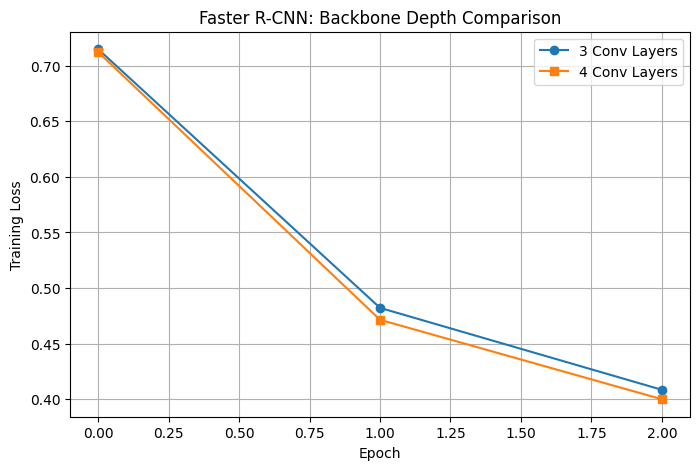

In [26]:
plt.figure(figsize=(8, 5))

plt.plot(
    history_3conv["train_loss"],
    marker="o",
    label="3 Conv Layers"
)

plt.plot(
    history_4conv["train_loss"],
    marker="s",
    label="4 Conv Layers"
)

plt.xlabel("Epoch")
plt.ylabel("Training Loss")
plt.title("Faster R-CNN: Backbone Depth Comparison")
plt.legend()
plt.grid(True)
plt.show()

In [27]:
def evaluate_detector(model, loader):

    model.eval()

    all_predictions = []
    all_ground_truths = []

    with torch.no_grad():

        for images, targets in loader:

            images = [
                img.to(device) for img in images
            ]

            outputs = model(images)

            for output, target in zip(outputs, targets):

                prediction = {
                    "boxes": output["boxes"].cpu().tolist(),
                    "scores": output["scores"].cpu().tolist(),
                    "labels": output["labels"].cpu().tolist()
                }

                ground_truth = {
                    "boxes": target["boxes"].cpu().tolist(),
                    "labels": target["labels"].cpu().tolist()
                }

                all_predictions.append(prediction)
                all_ground_truths.append(ground_truth)

    mean_ap = calculate_map(
        all_predictions,
        all_ground_truths,
        num_classes=2,
        iou_threshold=0.5
    )

    return mean_ap

In [28]:
print("Evaluating 3-Layer Model")

map_3conv = evaluate_detector(
    model_3conv, val_loader
)

print("\nEvaluating 4-Layer Model")

map_4conv = evaluate_detector(
    model_4conv, val_loader
)

print("\nFINAL COMPARISON")
print("-" * 40)

print(f"3-Layer mAP@0.5: {map_3conv:.4f}")
print(f"4-Layer mAP@0.5: {map_4conv:.4f}")

Evaluating 3-Layer Model
Class 1 AP: 0.2845

Evaluating 4-Layer Model
Class 1 AP: 0.1728

FINAL COMPARISON
----------------------------------------
3-Layer mAP@0.5: 0.2845
4-Layer mAP@0.5: 0.1728


In [29]:
import pandas as pd

results = pd.DataFrame({
    "Architecture": [
        "3 Conv Layers",
        "4 Conv Layers"
    ],
    "Parameters": [
        count_parameters(model_3conv),
        count_parameters(model_4conv)
    ],
    "Final Training Loss": [
        history_3conv["train_loss"][-1],
        history_4conv["train_loss"][-1]
    ],
    "Validation mAP@0.5": [
        map_3conv,
        map_4conv
    ],
    "Training Time (s)": [
        sum(history_3conv["epoch_time"]),
        sum(history_4conv["epoch_time"])
    ]
})

display(results)

,Architecture,Parameters,Final Training Loss,Validation mAP@0.5,Training Time (s)
0,3 Conv Layers,14886101,0.408517,0.284507,18.127823
1,4 Conv Layers,15476181,0.400052,0.172795,16.105875


In [30]:
torch.save(
    model_3conv.state_dict(),
    "/content/faster_rcnn_3conv.pth"
)

torch.save(
    model_4conv.state_dict(),
    "/content/faster_rcnn_4conv.pth"
)

results.to_csv(
    "/content/task1_results.csv",
    index=False
)

print("Models and results saved.")

Models and results saved.


## Analysis

Both models demonstrated decreasing training loss across the three epochs, indicating that optimization was progressing successfully.

The four-layer model achieved a slightly lower final training loss (0.4001) compared with the three-layer model (0.4085). However, its validation mAP@0.5 was considerably lower.

The three-layer backbone achieved a validation mAP of 28.45%, compared with 17.28% for the four-layer backbone.

This indicates that increasing the backbone depth did not improve detection performance under the tested conditions. The additional convolutional layer increased model complexity without providing a corresponding improvement in validation accuracy.

The lower validation mAP of the deeper model may be related to limited training, the small dataset, or optimization differences. Three epochs are insufficient to establish whether the deeper architecture would perform better after convergence.



# Task 2: Test Faster R-CNN on Real Images

In [31]:
import os
import torch
import matplotlib.pyplot as plt
import matplotlib.patches as patches
import numpy as np
import random

# Use previously trained model if available
if "model_3conv" not in globals():

    model_3conv = create_faster_rcnn(
        num_layers=3
    ).to(device)

    checkpoint_path = "/content/faster_rcnn_3conv.pth"

    if not os.path.exists(checkpoint_path):
        raise FileNotFoundError(
            "Checkpoint not found. Restore the saved checkpoint "
            "or rerun Task 1 training."
        )

    model_3conv.load_state_dict(
        torch.load(
            checkpoint_path,
            map_location=device,
            weights_only=True
        )
    )

model_3conv.eval()

print("3-layer Faster R-CNN ready for inference.")

3-layer Faster R-CNN ready for inference.


In [32]:
def visualize_detections(
    image,
    prediction,
    target=None,
    score_threshold=0.3,
    title="Faster R-CNN Detection"
):
    image_np = image.permute(1, 2, 0).cpu().numpy()

    fig, ax = plt.subplots(figsize=(10, 8))
    ax.imshow(image_np)

    # Ground-truth bounding boxes
    if target is not None:

        for box in target["boxes"]:
            xmin, ymin, xmax, ymax = box.cpu().tolist()

            rect = patches.Rectangle(
                (xmin, ymin),
                xmax - xmin,
                ymax - ymin,
                linewidth=2,
                edgecolor="lime",
                facecolor="none"
            )

            ax.add_patch(rect)

    # Predicted bounding boxes
    detected_count = 0

    for box, score, label in zip(
        prediction["boxes"],
        prediction["scores"],
        prediction["labels"]
    ):

        if score.item() < score_threshold:
            continue

        xmin, ymin, xmax, ymax = box.cpu().tolist()

        rect = patches.Rectangle(
            (xmin, ymin),
            xmax - xmin,
            ymax - ymin,
            linewidth=2,
            edgecolor="red",
            facecolor="none"
        )

        ax.add_patch(rect)

        ax.text(
            xmin,
            max(0, ymin - 5),
            f"Pedestrian: {score.item():.2f}",
            color="white",
            fontsize=10,
            bbox=dict(facecolor="red", alpha=0.8)
        )

        detected_count += 1

    ax.set_title(f"{title} | Predictions: {detected_count}")
    ax.axis("off")

    plt.show()


Validation Image Index: 7
Ground-truth objects: 1
Predictions (confidence >= 0.3): 0


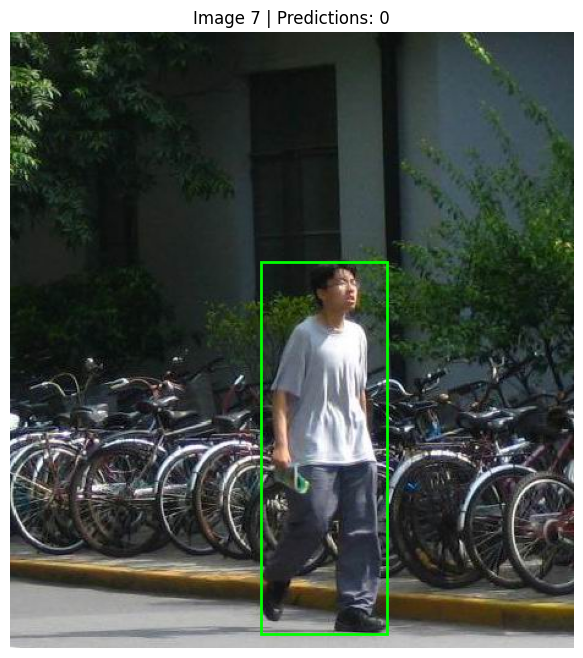


Validation Image Index: 1
Ground-truth objects: 1
Predictions (confidence >= 0.3): 0


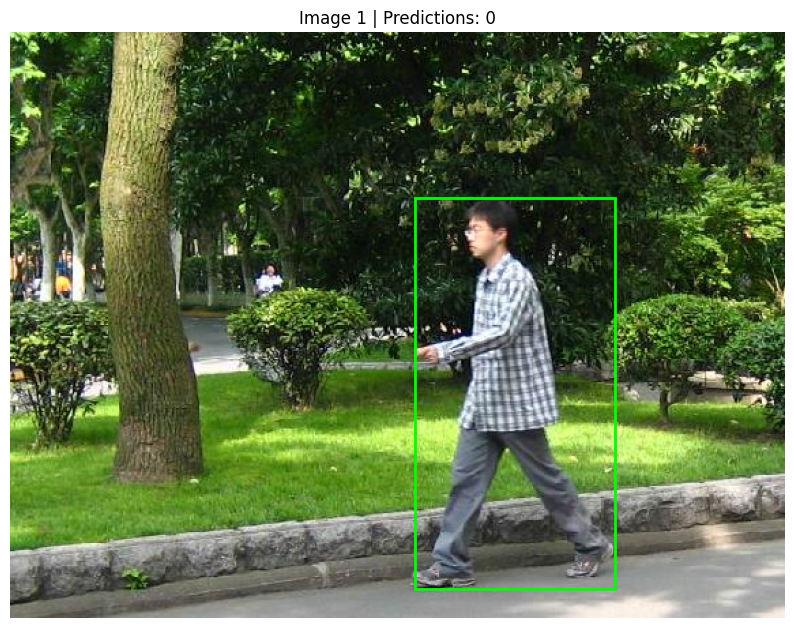


Validation Image Index: 17
Ground-truth objects: 2
Predictions (confidence >= 0.3): 0


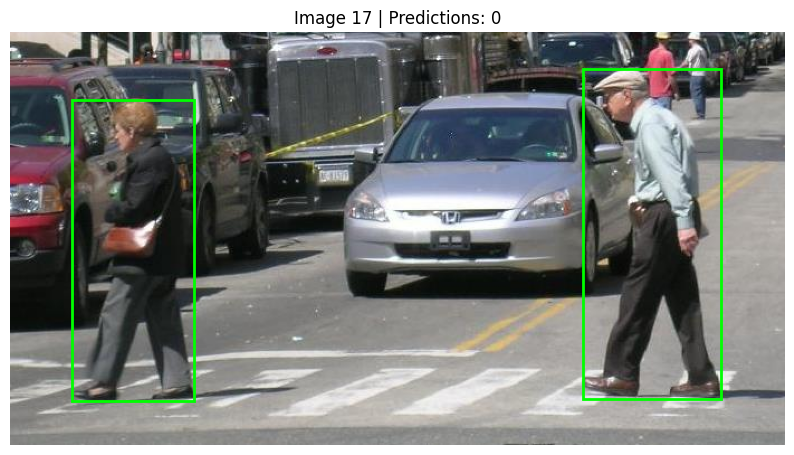


Validation Image Index: 15
Ground-truth objects: 1
Predictions (confidence >= 0.3): 0


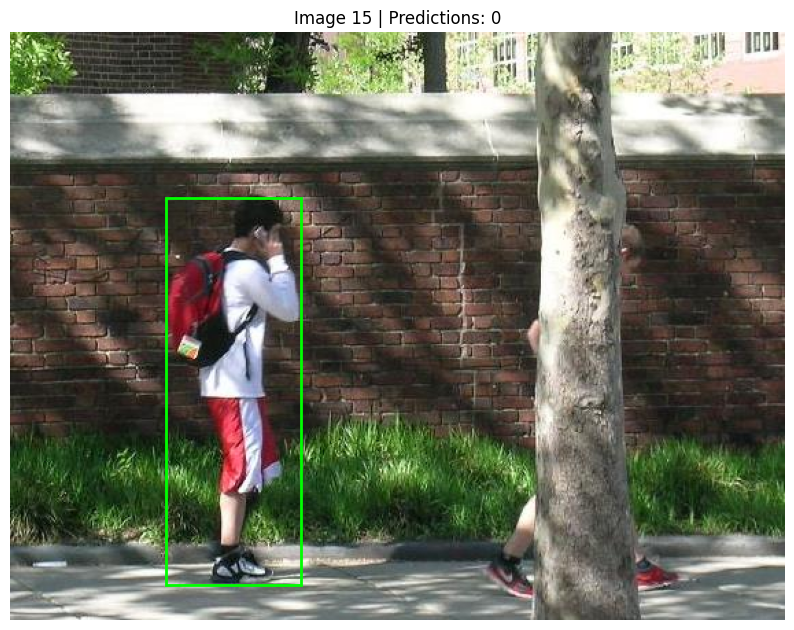


Validation Image Index: 14
Ground-truth objects: 1
Predictions (confidence >= 0.3): 0


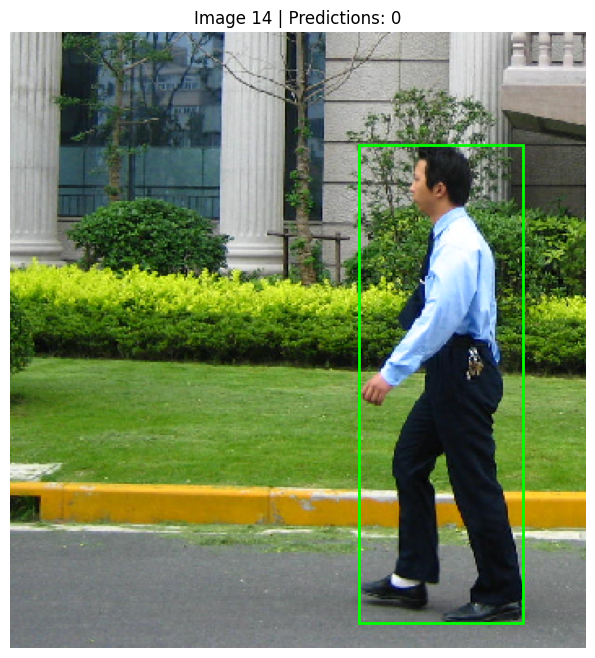

In [33]:
random.seed(42)

num_test_images = 5

selected_indices = random.sample(
    range(len(val_dataset)),
    k=min(num_test_images, len(val_dataset))
)

model_3conv.eval()

with torch.no_grad():

    for idx in selected_indices:

        image, target = val_dataset[idx]

        prediction = model_3conv(
            [image.to(device)]
        )[0]

        prediction = {
            key: value.cpu()
            for key, value in prediction.items()
        }

        print(f"\nValidation Image Index: {idx}")
        print("Ground-truth objects:", len(target["boxes"]))

        print(
            "Predictions (confidence >= 0.3):",
            (prediction["scores"] >= 0.3).sum().item()
        )

        visualize_detections(
            image=image,
            prediction=prediction,
            target=target,
            score_threshold=0.3,
            title=f"Image {idx}"
        )

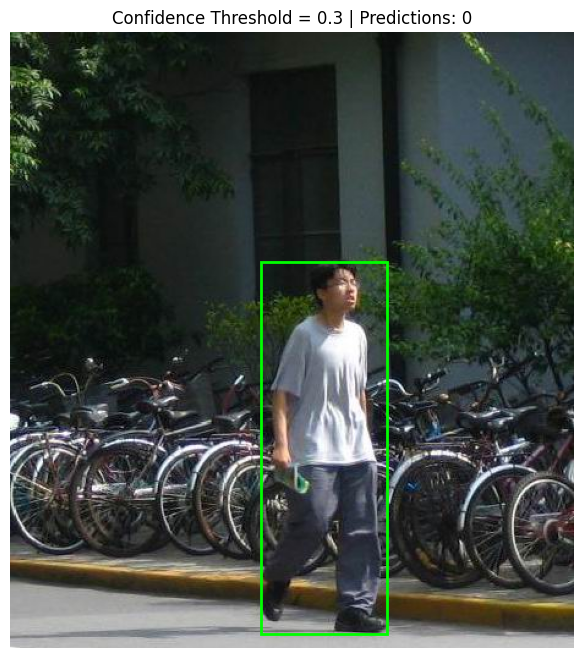

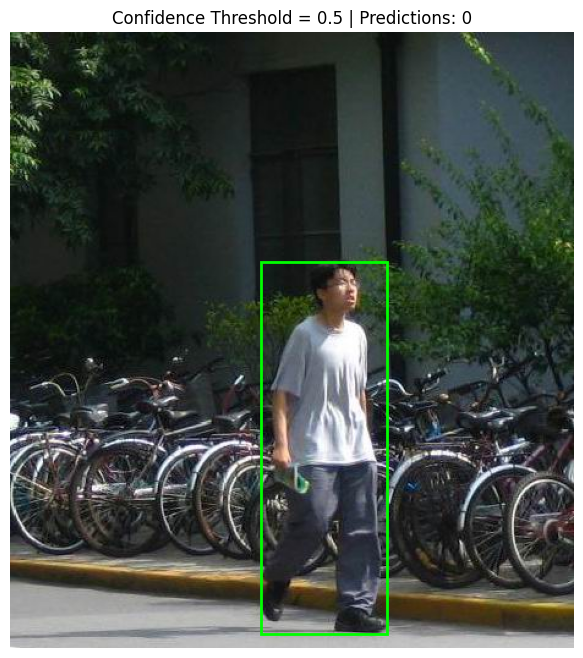

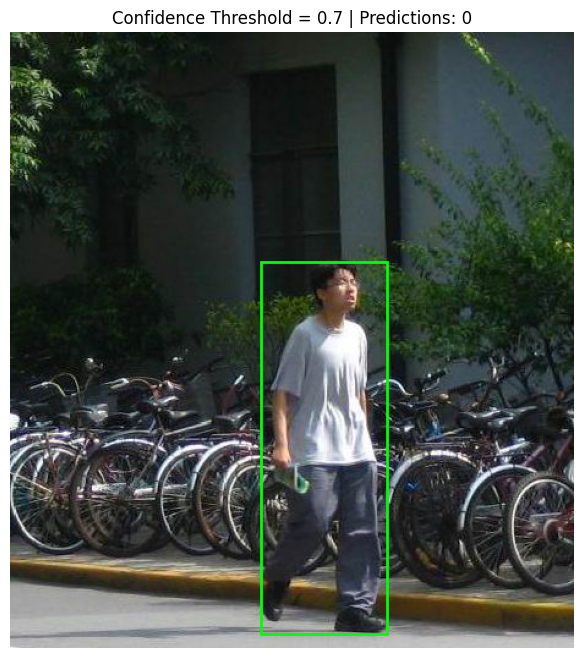

In [34]:
image, target = val_dataset[selected_indices[0]]

model_3conv.eval()

with torch.no_grad():
    prediction = model_3conv(
        [image.to(device)]
    )[0]

prediction = {
    key: value.cpu()
    for key, value in prediction.items()
}

for threshold in [0.3, 0.5, 0.7]:

    visualize_detections(
        image=image,
        prediction=prediction,
        target=target,
        score_threshold=threshold,
        title=f"Confidence Threshold = {threshold}"
    )

In [35]:
from torchvision.ops import box_iou

def evaluate_image_iou(
    prediction,
    target,
    score_threshold=0.5
):

    pred_boxes = prediction["boxes"][
        prediction["scores"] >= score_threshold
    ].cpu()

    gt_boxes = target["boxes"].cpu()

    if len(pred_boxes) == 0:
        print("No predictions above threshold.")
        return

    if len(gt_boxes) == 0:
        print("No ground-truth boxes.")
        return

    iou_matrix = box_iou(pred_boxes, gt_boxes)

    max_ious, best_gt_indices = iou_matrix.max(dim=1)

    print("Prediction | Best GT Match | IoU")
    print("-" * 40)

    for i, (iou, gt_idx) in enumerate(
        zip(max_ious, best_gt_indices)
    ):
        print(
            f"{i+1:^10} | "
            f"{gt_idx.item()+1:^13} | "
            f"{iou.item():.4f}"
        )

    print(
        "\nMean best-match IoU:",
        f"{max_ious.mean().item():.4f}"
    )


evaluate_image_iou(
    prediction,
    target,
    score_threshold=0.5
)

No predictions above threshold.


/usr/local/lib/python3.13/dist-packages/torchvision/utils.py:352: UserWarning: boxes doesn't contain any box. No box was drawn
  warnings.warn("boxes doesn't contain any box. No box was drawn")


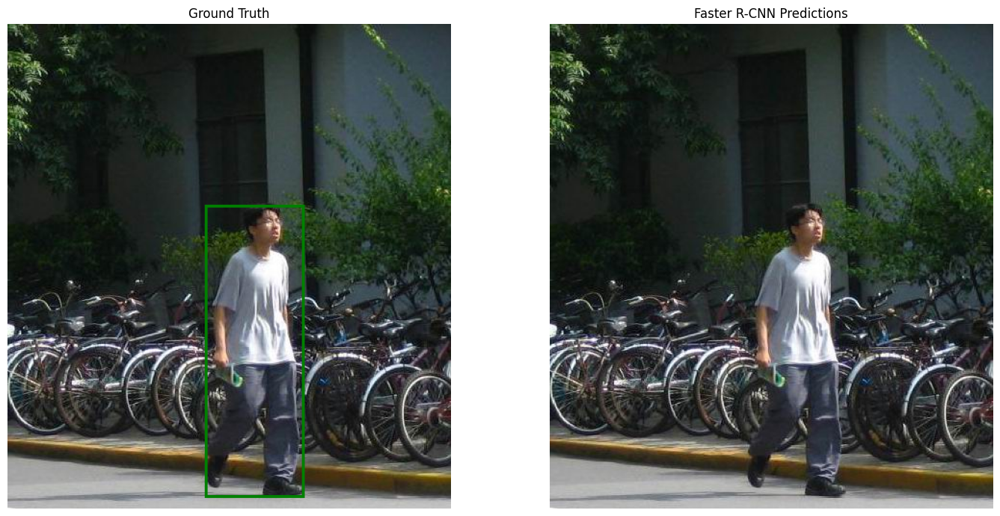

In [36]:
from torchvision.utils import draw_bounding_boxes
from torchvision.transforms.functional import to_pil_image

def compare_ground_truth_predictions(
    image,
    target,
    prediction,
    threshold=0.5
):

    image_uint8 = (
        image.cpu() * 255
    ).clamp(0, 255).to(torch.uint8)

    gt_image = draw_bounding_boxes(
        image_uint8,
        target["boxes"].cpu(),
        colors="green",
        width=3
    )

    keep = prediction["scores"] >= threshold

    pred_boxes = prediction["boxes"][keep].cpu()
    pred_scores = prediction["scores"][keep].cpu()

    labels = [
        f"Pedestrian {score:.2f}"
        for score in pred_scores.tolist()
    ]

    pred_image = draw_bounding_boxes(
        image_uint8,
        pred_boxes,
        labels=labels,
        colors="red",
        width=3
    )

    fig, axes = plt.subplots(1, 2, figsize=(15, 7))

    axes[0].imshow(to_pil_image(gt_image))
    axes[0].set_title("Ground Truth")

    axes[1].imshow(to_pil_image(pred_image))
    axes[1].set_title("Faster R-CNN Predictions")

    for ax in axes:
        ax.axis("off")

    plt.tight_layout()
    plt.show()


compare_ground_truth_predictions(
    image,
    target,
    prediction,
    threshold=0.5
)

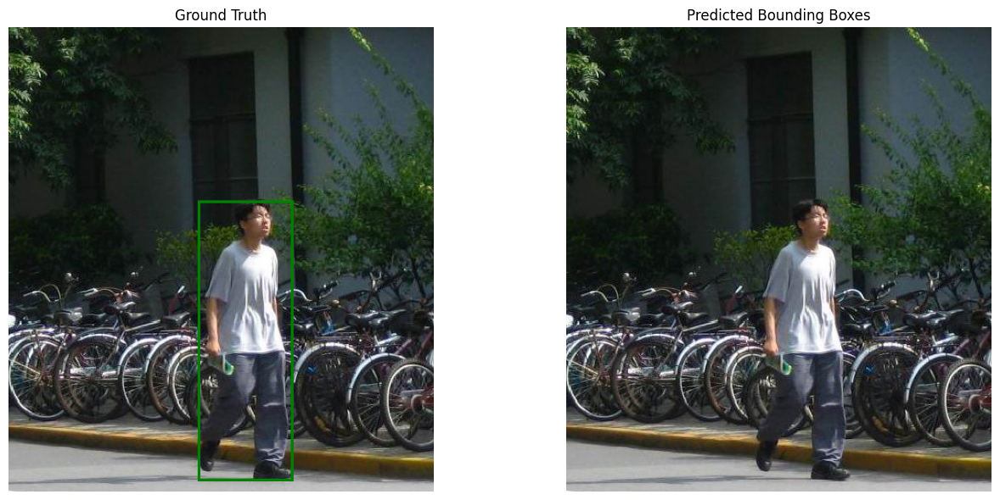

Saved: /content/task2_results/ground_truth_vs_predictions.png


In [37]:
import os

output_dir = "/content/task2_results"
os.makedirs(output_dir, exist_ok=True)

image, target = val_dataset[selected_indices[0]]

with torch.no_grad():
    prediction = model_3conv([image.to(device)])[0]

prediction = {
    key: value.cpu()
    for key, value in prediction.items()
}

image_uint8 = (
    image.cpu() * 255
).clamp(0, 255).to(torch.uint8)

gt_image = draw_bounding_boxes(
    image_uint8,
    target["boxes"].cpu(),
    colors="green",
    width=3
)

keep = prediction["scores"] >= 0.5

pred_image = draw_bounding_boxes(
    image_uint8,
    prediction["boxes"][keep],
    labels=[
        f"Pedestrian {s:.2f}"
        for s in prediction["scores"][keep].tolist()
    ],
    colors="red",
    width=3
)

fig, axes = plt.subplots(1, 2, figsize=(14, 6))

axes[0].imshow(to_pil_image(gt_image))
axes[0].set_title("Ground Truth")

axes[1].imshow(to_pil_image(pred_image))
axes[1].set_title("Predicted Bounding Boxes")

for ax in axes:
    ax.axis("off")

plt.tight_layout()

save_path = os.path.join(
    output_dir,
    "ground_truth_vs_predictions.png"
)

plt.savefig(save_path, dpi=200, bbox_inches="tight")
plt.show()

print("Saved:", save_path)

In [38]:
model_3conv.eval()

with torch.no_grad():
    for idx in selected_indices:
        image, target = val_dataset[idx]
        output = model_3conv([image.to(device)])[0]

        scores = output["scores"].cpu()

        print(f"\nImage {idx}")
        print("Ground-truth objects:", len(target["boxes"]))
        print("Detections returned:", len(scores))

        if len(scores) > 0:
            print("Highest confidence:", round(scores.max().item(), 4))
            print("Top 5 scores:", scores[:5].tolist())
        else:
            print("No detections returned by the model.")


Image 7
Ground-truth objects: 1
Detections returned: 61
Highest confidence: 0.2229
Top 5 scores: [0.22287315130233765, 0.22206318378448486, 0.2207915484905243, 0.21618886291980743, 0.20388852059841156]

Image 1
Ground-truth objects: 1
Detections returned: 41
Highest confidence: 0.2076
Top 5 scores: [0.2076084017753601, 0.18746717274188995, 0.17552253603935242, 0.15513665974140167, 0.14066092669963837]

Image 17
Ground-truth objects: 2
Detections returned: 63
Highest confidence: 0.2503
Top 5 scores: [0.25029683113098145, 0.22159996628761292, 0.2073909044265747, 0.19415532052516937, 0.19256967306137085]

Image 15
Ground-truth objects: 1
Detections returned: 49
Highest confidence: 0.2038
Top 5 scores: [0.20375913381576538, 0.17413946986198425, 0.16562563180923462, 0.1541377454996109, 0.14843343198299408]

Image 14
Ground-truth objects: 1
Detections returned: 38
Highest confidence: 0.1838
Top 5 scores: [0.18377089500427246, 0.15038242936134338, 0.14996518194675446, 0.13677816092967987, 0.

##Analysis

The model successfully completed inference on all five validation images. However, no predictions exceeded the selected confidence thresholds.

The ground-truth bounding boxes were correctly visualized, but no predicted bounding boxes were displayed.

Changing the visualization confidence threshold from 0.3 to 0.5 and 0.7 did not produce any additional detections.

Because no predictions exceeded the selected threshold of 0.5, IoU values could not be calculated for the displayed detections.

The model's limited performance may be associated with the short training duration, small dataset, and randomly initialized CNN backbone.

The earlier Task 1 validation mAP@0.5 of 28.45% indicates that some confidence-ranked predictions matched ground-truth objects across the validation dataset. However, this does not guarantee confident predictions on the five randomly selected images.

# Task 3: Training Faster R-CNN on the 150-image Bottle Dataset.

In [39]:
from google.colab import files
import zipfile
import os

uploaded = files.upload()

zip_filename = "BottleDataset_150_Clean.zip"
extract_dir = "/content/task3_data"

os.makedirs(extract_dir, exist_ok=True)

with zipfile.ZipFile(zip_filename, "r") as zip_ref:
    zip_ref.extractall(extract_dir)

dataset_root = os.path.join(extract_dir, "BottleDataset")

images_dir = os.path.join(dataset_root, "images")
labels_dir = os.path.join(dataset_root, "labels")

print("Total images:", len(os.listdir(images_dir)))
print("Total labels:", len(os.listdir(labels_dir)))

Saving BottleDataset_150_Clean.zip to BottleDataset_150_Clean.zip
Total images: 150
Total labels: 150


In [41]:
import os
import torch
from PIL import Image
from torch.utils.data import Dataset
from torchvision.transforms import functional as TF
from pathlib import Path

class CustomObjectDataset(Dataset):

    def __init__(self, images_dir, labels_dir):
        self.images_dir = Path(images_dir)
        self.labels_dir = Path(labels_dir)

        extensions = {".jpg", ".jpeg", ".png"}

        self.images = sorted([
            p for p in self.images_dir.iterdir()
            if p.suffix.lower() in extensions
        ])

    def __len__(self):
        return len(self.images)

    def __getitem__(self, idx):

        image_path = self.images[idx]
        label_path = self.labels_dir / (image_path.stem + ".txt")

        image = Image.open(image_path).convert("RGB")
        width, height = image.size

        boxes = []
        labels = []

        with open(label_path, "r") as f:
            for line in f:
                if not line.strip():
                    continue

                values = list(map(float, line.split()))

                if len(values) != 5:
                    raise ValueError(f"Invalid label: {label_path}")

                cls, xc, yc, bw, bh = values

                # YOLO normalized coordinates -> pixel coordinates
                x1 = (xc - bw / 2) * width
                y1 = (yc - bh / 2) * height
                x2 = (xc + bw / 2) * width
                y2 = (yc + bh / 2) * height

                x1 = max(0, min(width, x1))
                y1 = max(0, min(height, y1))
                x2 = max(0, min(width, x2))
                y2 = max(0, min(height, y2))

                if x2 <= x1 or y2 <= y1:
                    continue

                boxes.append([x1, y1, x2, y2])

                # YOLO class 0 -> Faster R-CNN class 1
                labels.append(int(cls) + 1)

        target = {
            "boxes": torch.tensor(
                boxes, dtype=torch.float32
            ).reshape(-1, 4),

            "labels": torch.tensor(
                labels, dtype=torch.int64
            ),

            "image_id": torch.tensor(idx)
        }

        return TF.to_tensor(image), target

In [42]:
custom_dataset = CustomObjectDataset(
    images_dir,
    labels_dir
)

print("Total dataset images:", len(custom_dataset))

image, target = custom_dataset[0]

print("Image shape:", image.shape)
print("Bounding boxes:", target["boxes"])
print("Labels:", target["labels"])

Total dataset images: 150
Image shape: torch.Size([3, 640, 640])
Bounding boxes: tensor([[272.7504,  75.7498, 381.2502, 517.2499]])
Labels: tensor([1])


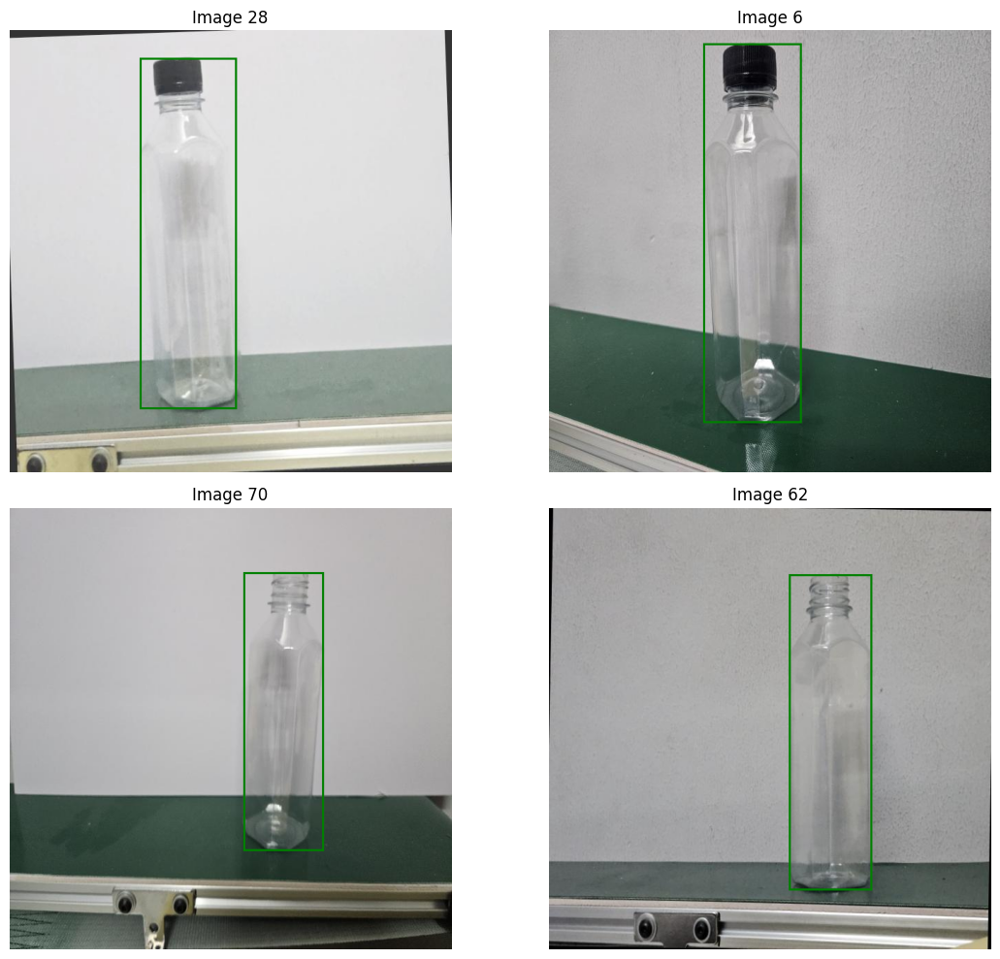

In [43]:
from torchvision.utils import draw_bounding_boxes
from torchvision.transforms.functional import to_pil_image
import matplotlib.pyplot as plt
import torch
import random

random.seed(42)

fig, axes = plt.subplots(2, 2, figsize=(12, 10))

for ax, idx in zip(
    axes.flatten(),
    random.sample(range(len(custom_dataset)), 4)
):
    image, target = custom_dataset[idx]

    image_uint8 = (image * 255).to(torch.uint8)

    annotated = draw_bounding_boxes(
        image_uint8,
        target["boxes"],
        colors="green",
        width=3
    )

    ax.imshow(to_pil_image(annotated))
    ax.set_title(f"Image {idx}")
    ax.axis("off")

plt.tight_layout()
plt.show()

In [44]:
import random
import numpy as np
import torch

from sklearn.model_selection import train_test_split
from torch.utils.data import DataLoader, Subset

SEED = 42

random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)

indices = list(range(len(custom_dataset)))

train_idx, remaining_idx = train_test_split(
    indices,
    test_size=0.30,
    random_state=SEED
)

val_idx, test_idx = train_test_split(
    remaining_idx,
    test_size=0.50,
    random_state=SEED
)

custom_train = Subset(custom_dataset, train_idx)
custom_val = Subset(custom_dataset, val_idx)
custom_test = Subset(custom_dataset, test_idx)

def custom_collate_fn(batch):
    return tuple(zip(*batch))

custom_train_loader = DataLoader(
    custom_train,
    batch_size=2,
    shuffle=True,
    collate_fn=custom_collate_fn,
    num_workers=2
)

custom_val_loader = DataLoader(
    custom_val,
    batch_size=2,
    shuffle=False,
    collate_fn=custom_collate_fn,
    num_workers=2
)

custom_test_loader = DataLoader(
    custom_test,
    batch_size=2,
    shuffle=False,
    collate_fn=custom_collate_fn,
    num_workers=2
)

print("Training images:", len(custom_train))
print("Validation images:", len(custom_val))
print("Testing images:", len(custom_test))

Training images: 105
Validation images: 22
Testing images: 23


In [45]:
from torchvision.models.detection import FasterRCNN
from torchvision.models.detection.rpn import AnchorGenerator
from torchvision.ops import MultiScaleRoIAlign

import torch.nn as nn

device = torch.device(
    "cuda" if torch.cuda.is_available() else "cpu"
)

class BottleBackbone(nn.Module):

    def __init__(self):
        super().__init__()

        self.features = nn.Sequential(
            nn.Conv2d(3, 64, 3, padding=1),
            nn.ReLU(inplace=True),
            nn.MaxPool2d(2),

            nn.Conv2d(64, 128, 3, padding=1),
            nn.ReLU(inplace=True),
            nn.MaxPool2d(2),

            nn.Conv2d(128, 256, 3, padding=1),
            nn.ReLU(inplace=True),
            nn.MaxPool2d(2)
        )

        self.out_channels = 256

    def forward(self, x):
        return self.features(x)


def create_bottle_detector():

    backbone = BottleBackbone()

    anchor_generator = AnchorGenerator(
        sizes=((32, 64, 128, 256, 512),),
        aspect_ratios=((0.5, 1.0, 2.0),)
    )

    roi_pooler = MultiScaleRoIAlign(
        featmap_names=["0"],
        output_size=7,
        sampling_ratio=2
    )

    model = FasterRCNN(
        backbone=backbone,
        num_classes=2,  # Background + Bottle
        rpn_anchor_generator=anchor_generator,
        box_roi_pool=roi_pooler,
        min_size=224,
        max_size=224
    )

    return model


torch.manual_seed(SEED)

task3_model = create_bottle_detector().to(device)

print("Device:", device)
print("Custom Faster R-CNN created successfully!")

print(
    "Trainable parameters:",
    sum(p.numel() for p in task3_model.parameters()
        if p.requires_grad)
)

Device: cuda
Custom Faster R-CNN created successfully!
Trainable parameters: 14886101


In [46]:
!pip -q install torchmetrics pycocotools

In [47]:
from torchmetrics.detection.mean_ap import MeanAveragePrecision

def evaluate_custom_map(model, data_loader):

    model.eval()

    metric = MeanAveragePrecision(
        box_format="xyxy",
        iou_type="bbox"
    )

    with torch.no_grad():
        for images, targets in data_loader:

            images = [
                image.to(device)
                for image in images
            ]

            outputs = model(images)

            predictions = [
                {
                    "boxes": output["boxes"].cpu(),
                    "scores": output["scores"].cpu(),
                    "labels": output["labels"].cpu()
                }
                for output in outputs
            ]

            ground_truths = [
                {
                    "boxes": target["boxes"].cpu(),
                    "labels": target["labels"].cpu()
                }
                for target in targets
            ]

            metric.update(predictions, ground_truths)

    results = metric.compute()

    return {
        "map50": results["map_50"].item(),
        "map5095": results["map"].item()
    }

In [48]:
import copy
import time

def train_custom_detector(
    model,
    train_loader,
    val_loader,
    epochs=15,
    patience=5
):

    optimizer = torch.optim.Adam(
        model.parameters(),
        lr=0.0001,
        weight_decay=0.0005
    )

    history = {
        "train_loss": [],
        "val_map50": [],
        "val_map5095": []
    }

    best_map = -1.0
    best_epoch = 0
    best_weights = None
    no_improvement = 0

    for epoch in range(epochs):

        start_time = time.time()
        model.train()

        total_loss = 0.0

        for images, targets in train_loader:

            images = [
                image.to(device)
                for image in images
            ]

            targets = [
                {
                    key: value.to(device)
                    for key, value in target.items()
                }
                for target in targets
            ]

            optimizer.zero_grad()

            loss_dict = model(images, targets)
            loss = sum(loss_dict.values())

            if not torch.isfinite(loss):
                raise RuntimeError(
                    f"Non-finite loss at epoch {epoch + 1}"
                )

            loss.backward()
            optimizer.step()

            total_loss += loss.item()

        avg_loss = total_loss / len(train_loader)

        val_metrics = evaluate_custom_map(
            model, val_loader
        )

        val_map50 = val_metrics["map50"]
        val_map5095 = val_metrics["map5095"]

        history["train_loss"].append(avg_loss)
        history["val_map50"].append(val_map50)
        history["val_map5095"].append(val_map5095)

        elapsed = time.time() - start_time

        print(
            f"Epoch {epoch+1}/{epochs} | "
            f"Loss: {avg_loss:.4f} | "
            f"Val mAP@0.5: {val_map50:.4f} | "
            f"Val mAP@0.5:0.95: {val_map5095:.4f} | "
            f"Time: {elapsed:.1f}s"
        )

        if val_map50 > best_map + 1e-6:

            best_map = val_map50
            best_epoch = epoch + 1

            best_weights = {
                k: v.detach().cpu().clone()
                for k, v in model.state_dict().items()
            }

            no_improvement = 0

        else:
            no_improvement += 1

        if no_improvement >= patience:
            print("Early stopping triggered.")
            break

    if best_weights is not None:
        model.load_state_dict(best_weights)

    print("\nTraining completed!")
    print("Best epoch:", best_epoch)
    print(f"Best validation mAP@0.5: {best_map:.4f}")

    return model, history

In [49]:
task3_model, task3_history = train_custom_detector(
    model=task3_model,
    train_loader=custom_train_loader,
    val_loader=custom_val_loader,
    epochs=15,
    patience=5
)

Epoch 1/15 | Loss: 0.5678 | Val mAP@0.5: 0.0278 | Val mAP@0.5:0.95: 0.0077 | Time: 7.6s
Epoch 2/15 | Loss: 0.3191 | Val mAP@0.5: 0.5867 | Val mAP@0.5:0.95: 0.2668 | Time: 5.7s
Epoch 3/15 | Loss: 0.2792 | Val mAP@0.5: 0.6677 | Val mAP@0.5:0.95: 0.3252 | Time: 4.7s
Epoch 4/15 | Loss: 0.2684 | Val mAP@0.5: 0.7789 | Val mAP@0.5:0.95: 0.3528 | Time: 4.1s
Epoch 5/15 | Loss: 0.2696 | Val mAP@0.5: 0.9479 | Val mAP@0.5:0.95: 0.4052 | Time: 4.4s
Epoch 6/15 | Loss: 0.2417 | Val mAP@0.5: 0.8837 | Val mAP@0.5:0.95: 0.4985 | Time: 4.5s
Epoch 7/15 | Loss: 0.2328 | Val mAP@0.5: 0.8965 | Val mAP@0.5:0.95: 0.3837 | Time: 4.0s
Epoch 8/15 | Loss: 0.2161 | Val mAP@0.5: 0.9917 | Val mAP@0.5:0.95: 0.4348 | Time: 4.3s
Epoch 9/15 | Loss: 0.2162 | Val mAP@0.5: 0.9957 | Val mAP@0.5:0.95: 0.4971 | Time: 4.4s
Epoch 10/15 | Loss: 0.2122 | Val mAP@0.5: 0.9978 | Val mAP@0.5:0.95: 0.4719 | Time: 3.9s
Epoch 11/15 | Loss: 0.2093 | Val mAP@0.5: 1.0000 | Val mAP@0.5:0.95: 0.4293 | Time: 4.0s
Epoch 12/15 | Loss: 0.2029 | V

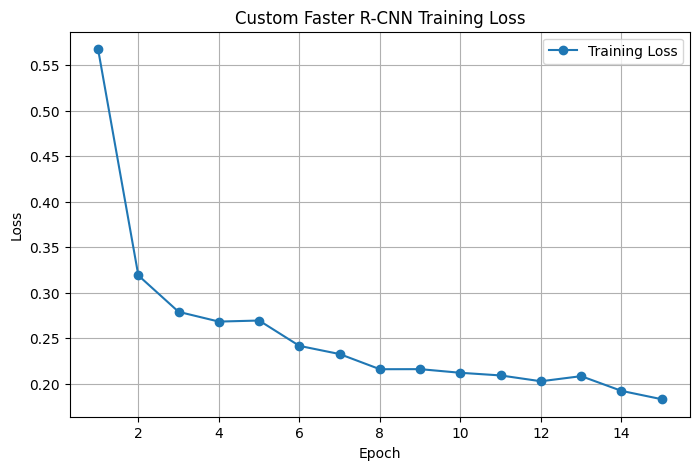

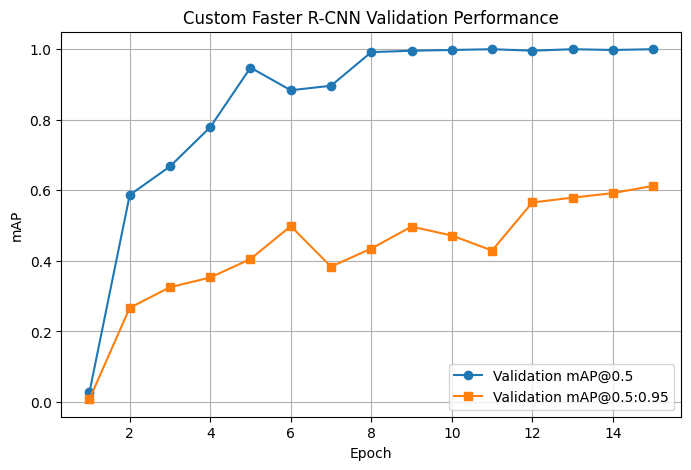

In [50]:
epochs_run = range(
    1, len(task3_history["train_loss"]) + 1
)

plt.figure(figsize=(8, 5))

plt.plot(
    epochs_run,
    task3_history["train_loss"],
    marker="o",
    label="Training Loss"
)

plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.title("Custom Faster R-CNN Training Loss")
plt.legend()
plt.grid(True)
plt.show()


plt.figure(figsize=(8, 5))

plt.plot(
    epochs_run,
    task3_history["val_map50"],
    marker="o",
    label="Validation mAP@0.5"
)

plt.plot(
    epochs_run,
    task3_history["val_map5095"],
    marker="s",
    label="Validation mAP@0.5:0.95"
)

plt.xlabel("Epoch")
plt.ylabel("mAP")
plt.title("Custom Faster R-CNN Validation Performance")
plt.legend()
plt.grid(True)
plt.show()

In [51]:
test_metrics = evaluate_custom_map(
    task3_model,
    custom_test_loader
)

print("FINAL TEST RESULTS")
print("-" * 40)

print(
    f"Test mAP@0.5: "
    f"{test_metrics['map50']:.4f}"
)

print(
    f"Test mAP@0.5:0.95: "
    f"{test_metrics['map5095']:.4f}"
)

FINAL TEST RESULTS
----------------------------------------
Test mAP@0.5: 0.7921
Test mAP@0.5:0.95: 0.3570


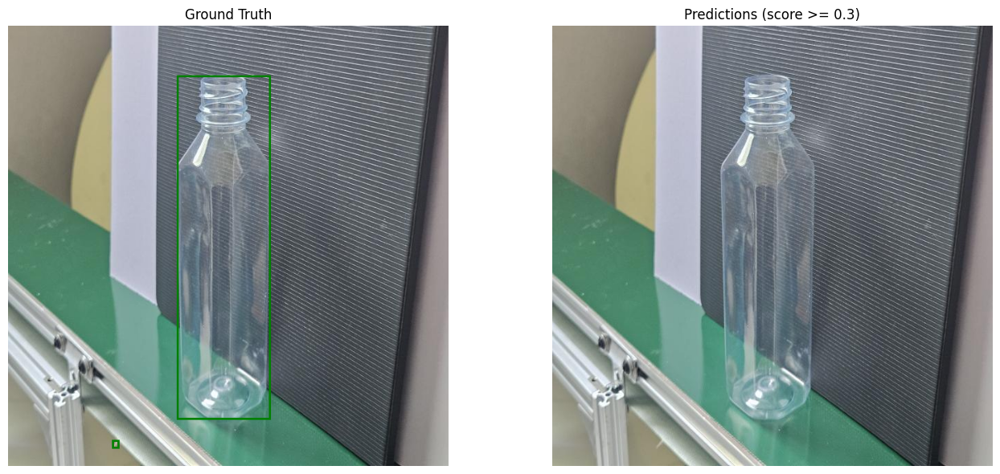

Test image index: 1
Actual bottles: 2
Predicted bottles: 0


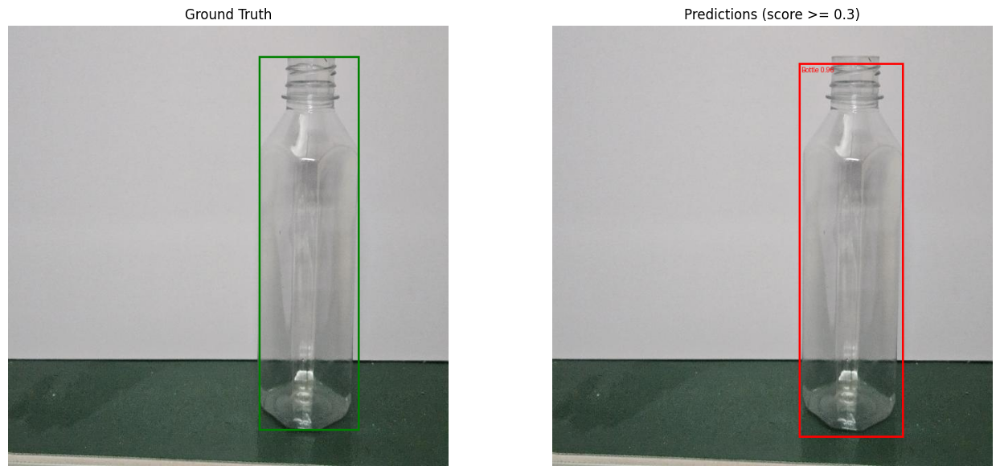

Test image index: 8
Actual bottles: 1
Predicted bottles: 1


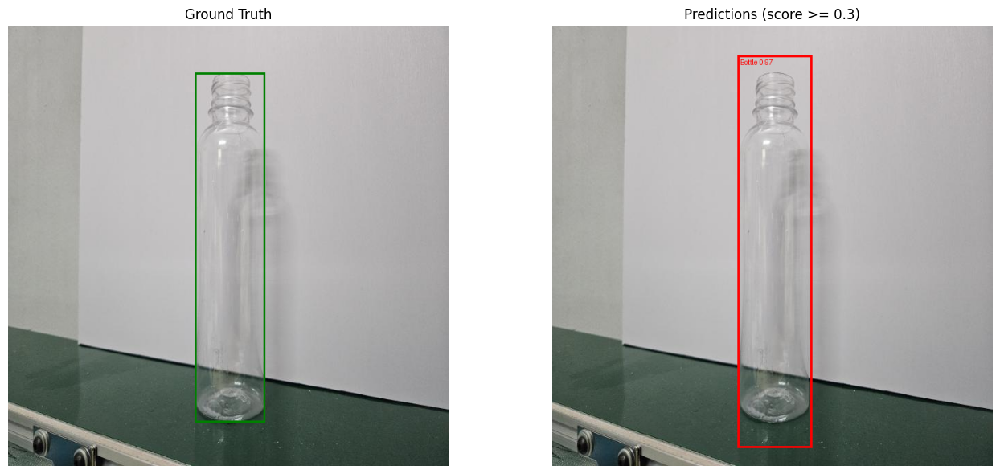

Test image index: 2
Actual bottles: 1
Predicted bottles: 1


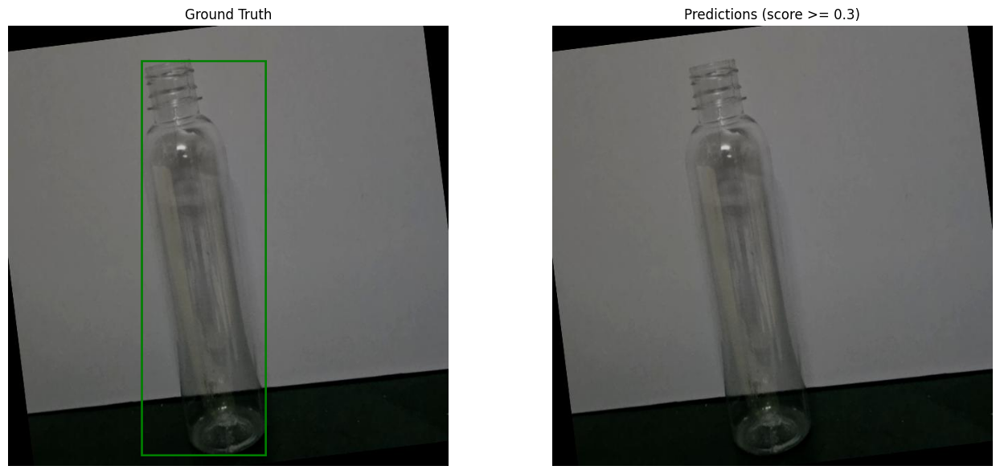

Test image index: 13
Actual bottles: 1
Predicted bottles: 0


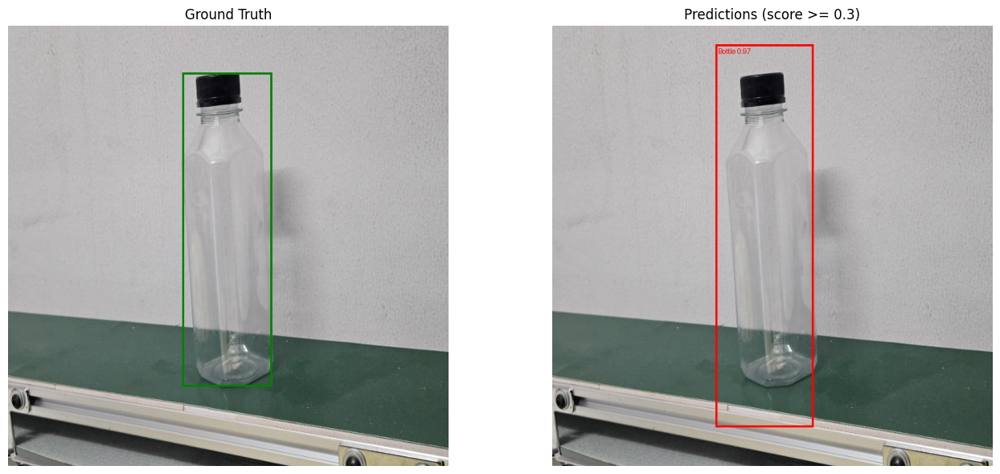

Test image index: 3
Actual bottles: 1
Predicted bottles: 1


In [52]:
from torchvision.utils import draw_bounding_boxes
from torchvision.transforms.functional import to_pil_image

def show_bottle_predictions(
    model,
    dataset,
    num_images=5,
    threshold=0.3
):

    model.eval()

    random.seed(123)

    sample_indices = random.sample(
        range(len(dataset)),
        min(num_images, len(dataset))
    )

    with torch.no_grad():

        for idx in sample_indices:

            image, target = dataset[idx]

            prediction = model(
                [image.to(device)]
            )[0]

            prediction = {
                k: v.cpu()
                for k, v in prediction.items()
            }

            keep = prediction["scores"] >= threshold

            image_uint8 = (
                image * 255
            ).clamp(0, 255).to(torch.uint8)

            gt_image = draw_bounding_boxes(
                image_uint8,
                target["boxes"],
                colors="green",
                width=3
            )

            pred_boxes = prediction["boxes"][keep]
            pred_scores = prediction["scores"][keep]

            if len(pred_boxes) > 0:
                pred_image = draw_bounding_boxes(
                    image_uint8,
                    pred_boxes,
                    labels=[
                        f"Bottle {score:.2f}"
                        for score in pred_scores.tolist()
                    ],
                    colors="red",
                    width=3
                )
            else:
                pred_image = image_uint8

            fig, axes = plt.subplots(
                1, 2, figsize=(14, 6)
            )

            axes[0].imshow(to_pil_image(gt_image))
            axes[0].set_title("Ground Truth")

            axes[1].imshow(to_pil_image(pred_image))
            axes[1].set_title(
                f"Predictions (score >= {threshold})"
            )

            for ax in axes:
                ax.axis("off")

            plt.tight_layout()
            plt.show()

            print(f"Test image index: {idx}")
            print("Actual bottles:", len(target["boxes"]))
            print("Predicted bottles:", len(pred_boxes))


show_bottle_predictions(
    task3_model,
    custom_test,
    num_images=5,
    threshold=0.3
)

In [53]:
import os
import pandas as pd

save_dir = "/content/task3_results"
os.makedirs(save_dir, exist_ok=True)

torch.save(
    task3_model.state_dict(),
    f"{save_dir}/custom_faster_rcnn_bottle.pth"
)

history_df = pd.DataFrame(task3_history)

history_df.to_csv(
    f"{save_dir}/training_history.csv",
    index=False
)

results_df = pd.DataFrame([{
    "Model": "Custom Faster R-CNN",
    "Train Images": len(custom_train),
    "Validation Images": len(custom_val),
    "Test Images": len(custom_test),
    "Test mAP@0.5": test_metrics["map50"],
    "Test mAP@0.5:0.95": test_metrics["map5095"]
}])

results_df.to_csv(
    f"{save_dir}/test_results.csv",
    index=False
)

display(results_df)

print("Results saved to:", save_dir)

,Model,Train Images,Validation Images,Test Images,Test mAP@0.5,Test mAP@0.5:0.95
0,Custom Faster R-CNN,105,22,23,0.792079,0.357036


Results saved to: /content/task3_results


## Prediction Analysis

Five randomly selected test images were visualized using a confidence threshold of 0.3.

The model produced three detections across these five images, while the images contained six annotated bottles.

Some objects were detected, but other objects did not produce predictions above the selected confidence threshold.

This indicates that the model's detection performance remains imperfect despite the relatively high dataset-level mAP@0.5.